# What does one extraction round cost the data?

**`p_stab` is the quantity the paper declares and we have to measure.** It is the probability
that running one syndrome round inflicts an X fault on a given data qubit, at τ=0. Everything
downstream — λ, the `b_read` floor, where the τ optimum can sit — is a ratio built on it.

Their model sets `p_stab = p` and moves on. Ours is an output of the circuit, so it has to be
derived:

| step | what it settles |
| --- | --- |
| 1 | a proxy that makes a per-qubit fault observable at all |
| 2 | ops per data qubit per round, from the slope in R |
| 3 | whether `p_stab` is one number or seven |
| 4 | how `p_1q` and `p_2q` each contribute |
| 5 | the same count read off the compiled circuit |
| 6 | λ and the `b_read` floor |

**Headline: `p_stab` is not a scalar.** It tracks how many Z-checks a data qubit sits in, so
it comes in three values across the seven qubits, in the ratio the stabiliser structure
predicts.

## 0. Setup

In [1]:
%matplotlib inline
import pathlib
import matplotlib.pyplot as plt

# Reference palette, fixed order. Slots 1-3 validate under all-pairs comparison.
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRAY, INK, MUTED = '#8a8a86', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c9c4', 'axes.labelcolor': MUTED, 'axes.titlesize': 10,
    'axes.labelsize': 9, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'grid.color': '#e6e6e1',
    'legend.frameon': False, 'legend.fontsize': 8, 'font.size': 9, 'text.color': INK,
})
FIGDIR = pathlib.Path('figures'); FIGDIR.mkdir(exist_ok=True)


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()


import numpy as np
import pandas as pd

from guppylang import guppy
from guppylang.std.angles import angle
from guppylang.std.builtins import array, output, py
from guppylang.std.quantum import collect_measurements, cx, h, measure, measure_array, qubit
from guppylang.std.qsystem import phased_x
from selene_sim import DepolarizingErrorModel, IdealErrorModel, Quest, build

SHOTS = 6000
N_QUBITS = 16
pd.set_option('display.width', 140)

# Z-stabilisers of Steane [[7,1,3]]. The multiplicity of each data qubit across
# these three checks is what the per-qubit cost should follow.
Z_CHECKS = [(0, 2, 4, 6), (1, 2, 5, 6), (3, 4, 5, 6)]
MULT = np.array([sum(q in c for c in Z_CHECKS) for q in range(7)])

_BUILT = {}


def run(key, make, shots=SHOTS, seed=1, **channels):
    if key not in _BUILT:
        _BUILT[key] = build(make().compile())
    return [dict(s) for s in _BUILT[key].run_shots(
        simulator=Quest(), n_qubits=N_QUBITS, n_shots=shots,
        error_model=DepolarizingErrorModel(random_seed=seed, **channels),
        random_seed=seed)]


def flip_per_op(p_1q):
    """Z-basis flip probability per charged 1q op: X and Y flip |0>, Z does not."""
    return 2 * p_1q / 3


def n_effective(rate, p_1q):
    """Invert accumulate(): how many charged ops produce this flip rate."""
    f = flip_per_op(p_1q)
    r = np.clip(np.asarray(rate, float), 0, 0.4999)
    return np.log(1 - 2 * r) / np.log(1 - 2 * f)


def sigma(p, n=SHOTS):
    return np.sqrt(np.maximum(p * (1 - p), 1e-12) / n)


print(f"data-qubit multiplicity across the three Z-checks: {MULT.tolist()}")
print(f"(sum = {MULT.sum()}, which is the 12 CNOTs of one round)")


data-qubit multiplicity across the three Z-checks: [1, 1, 2, 1, 2, 2, 3]
(sum = 12, which is the 12 CNOTs of one round)


## 1. A proxy that makes the fault observable

`|0_L>` cannot be used here. Measuring it in Z returns a random one of 8 codewords, so a
per-qubit "flip" has no meaning.

**Use a product state instead: `|0>^7`, then run the extraction CNOTs.** With every data qubit
in `|0>` the ancillas stay in `|0>` and nothing entangles — the circuit is logically inert —
but the gate sequence and every charged operation in it are identical. So any data qubit
reading 1 is an X fault on that qubit, read directly.

Two confounds disappear with it: there is no encoder, and there is no idling. At τ=0 the only
thing that can flip a data qubit is the round itself.

In [2]:
def proxy(rounds):
    """|0>^7, `rounds` extraction rounds, measure the data. No encoder, no idling."""
    @guppy
    def prog() -> None:
        qs = array(qubit() for _ in range(7))
        for _ in range(py(rounds)):
            a0, a1, a2 = qubit(), qubit(), qubit()
            cx(qs[0], a0); cx(qs[2], a0); cx(qs[4], a0); cx(qs[6], a0)
            cx(qs[1], a1); cx(qs[2], a1); cx(qs[5], a1); cx(qs[6], a1)
            cx(qs[3], a2); cx(qs[4], a2); cx(qs[5], a2); cx(qs[6], a2)
            output("s", array(measure(a0).read(), measure(a1).read(), measure(a2).read()))
        output("data", collect_measurements(measure_array(qs)))
    return prog


def data_rates(rounds, **channels):
    """Per-data-qubit flip probability after `rounds` extraction rounds."""
    shots = run(("proxy", rounds), lambda r=rounds: proxy(r), **channels)
    m = np.array([[int(b) for b in s["data"]] for s in shots], dtype=float)
    return m.mean(axis=0)


P1Q = 0.006
ROUNDS = (1, 2, 4, 6, 8)

raw = {r: data_rates(r, p_1q=P1Q) for r in ROUNDS}
tab = pd.DataFrame(raw, index=[f"q{i}" for i in range(7)]).T
tab.index.name = "rounds"
print(f"per-data-qubit flip rate, p_1q = {P1Q}, {SHOTS} shots (sigma ~ {sigma(0.03):.4f})\n")
tab.round(4)


per-data-qubit flip rate, p_1q = 0.006, 6000 shots (sigma ~ 0.0022)



,q0,q1,q2,q3,q4,q5,q6
rounds,,,,,,,
1,0.0032,0.0048,0.0087,0.0058,0.0087,0.0082,0.0117
2,0.0085,0.0070,0.0170,0.0107,0.0185,0.0145,0.0223
4,0.0165,0.0147,0.0320,0.0200,0.0352,0.0298,0.0435
6,0.0240,0.0222,0.0473,0.0267,0.0503,0.0433,0.0648
8,0.0293,0.0297,0.0643,0.0350,0.0647,0.0565,0.0843


## 2. Ops per data qubit per round

Flips compose mod 2, so a rate inverts to a count of charged operations:

```
n_eff = log(1 - 2·rate) / log(1 - 2f),      f = 2·p_1q/3
```

If the round is the only thing acting, `n_eff` must be **linear in R with zero intercept**.
A non-zero intercept means something outside the round is contributing and the decomposition
is wrong.

In [3]:
neff = pd.DataFrame({r: n_effective(v, P1Q) for r, v in raw.items()},
                    index=[f"q{i}" for i in range(7)]).T
neff.index.name = "rounds"
print("effective charged ops accumulated on each data qubit\n")
print(neff.round(2))

R = np.array(ROUNDS, float)
slope, intercept = [], []
for q in neff.columns:
    a, b = np.polyfit(R, neff[q].values, 1)
    slope.append(a); intercept.append(b)

fit = pd.DataFrame({'ops per round': slope, 'intercept': intercept,
                    'Z-check multiplicity': MULT},
                   index=neff.columns)
fit['ops per check'] = fit['ops per round'] / fit['Z-check multiplicity']
print("\n", fit.round(2).to_string())
print(f"\nlargest |intercept|: {max(abs(np.array(intercept))):.2f} ops"
      f"  -- consistent with zero means the round is the only contributor")


effective charged ops accumulated on each data qubit

          q0    q1     q2    q3     q4     q5     q6
rounds                                              
1       0.79  1.21   2.18  1.46   2.18   2.05   2.94
2       2.13  1.76   4.31  2.68   4.69   3.66   5.69
4       4.18  3.71   8.23  5.08   9.08   7.66  11.33
6       6.12  5.65  12.38  6.82  13.21  11.29  17.29
8       7.53  7.62  17.15  9.04  17.24  14.93  23.00

     ops per round  intercept  Z-check multiplicity  ops per check
q0           0.96       0.11                     1           0.96
q1           0.93       0.06                     1           0.93
q2           2.11      -0.03                     2           1.06
q3           1.07       0.53                     1           1.07
q4           2.14       0.29                     2           1.07
q5           1.86       0.12                     2           0.93
q6           2.88      -0.03                     3           0.96

largest |intercept|: 0.53 ops  -- consistent

## 3. Is `p_stab` one number or seven?

The paper's `p_stab` is a single scalar applied to every data qubit. Ours cannot be, if the
cost tracks how many checks a qubit participates in.

`q6` sits in all three Z-checks, `q2`/`q4`/`q5` in two, `q0`/`q1`/`q3` in one. If the round's
cost is carried by the CNOTs, the per-qubit cost should follow `1:1:2:1:2:2:3` exactly, and
the `ops per check` column above should be flat.

In [4]:
ops_per_check = fit['ops per check'].values
print(f"ops per check, across the seven data qubits: "
      f"{np.round(ops_per_check, 2).tolist()}")
print(f"  mean {ops_per_check.mean():.2f}, spread {np.ptp(ops_per_check):.2f}")

pred = MULT * ops_per_check.mean()
cmp = pd.DataFrame({'measured ops/round': np.round(slope, 2),
                    'predicted from multiplicity': np.round(pred, 2)},
                   index=neff.columns)
print("\n", cmp.to_string())

p_stab = np.array([(1 - (1 - 2 * flip_per_op(P1Q)) ** s) / 2 for s in slope])
ps = pd.Series(p_stab, index=neff.columns, name=f"p_stab at p_1q={P1Q}")
print(f"\n{ps.round(5).to_string()}")
print(f"\np_stab spans {p_stab.min():.5f} to {p_stab.max():.5f} "
      f"- a factor of {p_stab.max() / p_stab.min():.1f} across the block.")


ops per check, across the seven data qubits: [0.96, 0.93, 1.06, 1.07, 1.07, 0.93, 0.96]
  mean 1.00, spread 0.14

     measured ops/round  predicted from multiplicity
q0                0.96                         1.00
q1                0.93                         1.00
q2                2.11                         1.99
q3                1.07                         1.00
q4                2.14                         1.99
q5                1.86                         1.99
q6                2.88                         2.99

q0    0.00385
q1    0.00374
q2    0.00842
q3    0.00427
q4    0.00852
q5    0.00740
q6    0.01142

p_stab spans 0.00374 to 0.01142 - a factor of 3.1 across the block.


## 4. Splitting `p_1q` from `p_2q`

Both channels land on a CNOT. At small rates their contributions add:

```
p_stab  ≈  a·p_1q  +  b·p_2q
```

`p_2q` matters for two reasons. It is the only knob that loads the extraction without touching
idling, so it is the continuous lever on λ. And a two-qubit depolarizing fault spans data and
ancilla together, which is the correlated event the phenomenological model cannot express.

For a 2-qubit depolarizing channel, 8 of the 15 non-identity Paulis flip a given qubit, so the
per-CX flip contribution is `8·p_2q/15`.

In [5]:
RS = 4
conds = [("p_1q only", dict(p_1q=P1Q)),
         ("p_2q only", dict(p_2q=P1Q)),
         ("both", dict(p_1q=P1Q, p_2q=P1Q))]

split = {}
for label, ch in conds:
    split[label] = data_rates(RS, **ch)

sp = pd.DataFrame(split, index=[f"q{i}" for i in range(7)])
sp['sum of singles'] = sp['p_1q only'] + sp['p_2q only']
print(f"flip rate after {RS} rounds, {SHOTS} shots (sigma ~ {sigma(0.05):.4f})\n")
print(sp.round(4).to_string())

resid = (sp['both'] - sp['sum of singles']).abs().max()
print(f"\nlargest departure from additivity: {resid:.4f} (sigma ~ {sigma(0.05):.4f})")
print(f"\nper-CX flip contribution, p_2q: measured "
      f"{(sp['p_2q only'] / (RS * MULT)).mean():.5f}  vs  8/15 * p_2q = {8 * P1Q / 15:.5f}")


flip rate after 4 rounds, 6000 shots (sigma ~ 0.0028)

    p_1q only  p_2q only    both  sum of singles
q0     0.0165     0.0148  0.0313          0.0313
q1     0.0147     0.0132  0.0275          0.0278
q2     0.0320     0.0217  0.0523          0.0537
q3     0.0200     0.0098  0.0295          0.0298
q4     0.0352     0.0277  0.0612          0.0628
q5     0.0298     0.0235  0.0523          0.0533
q6     0.0435     0.0343  0.0752          0.0778

largest departure from additivity: 0.0027 (sigma ~ 0.0028)

per-CX flip contribution, p_2q: measured 0.00306  vs  8/15 * p_2q = 0.00320


## 5. The same count, read off the compiled circuit

The slope in section 2 infers the operation count from measured error. `CircuitExtractor`
reads it directly: `get_error_model_input()` returns the native operations exactly as the
error model receives them, which is the definition of what gets charged.

**One trap worth recording.** `run_shots` is a generator whose `with TCPStream(...)` block
spans the entire shot loop, and each value it yields is itself a *lazy* generator. So
`list(run_shots(...))` runs the loop to completion without reading a single shot, exits the
`with`, closes the results socket -- and the child process, still starting up, dies with
`ConnectionRefused`. Every shot must be consumed as it arrives.

Two independent routes to one number. They have to agree, and the `h = 2 ops` result from
`03_noise_channel_audit` is the reason not to assume they will.

In [6]:
from selene_sim.event_hooks.instruction_log import CircuitExtractor

hook = CircuitExtractor()
# Consume each shot as it arrives. `run_shots` is a generator whose `with TCPStream`
# block wraps the whole loop and whose yields are themselves lazy generators, so
# list(run_shots(...)) materialises the loop without reading anything, closes the
# results socket, and the still-starting child dies with ConnectionRefused.
for _shot in build(proxy(1).compile()).run_shots(
        simulator=Quest(), n_qubits=N_QUBITS, n_shots=1,
        error_model=IdealErrorModel(), random_seed=1, event_hook=hook):
    list(_shot)

ops = hook.shots[0].get_error_model_input()
counts_1q, counts_2q = {}, {}
for o in ops:
    name = o.get('op')
    if name in ('Rxy', 'Rz'):
        counts_1q[o['qubit']] = counts_1q.get(o['qubit'], 0) + 1
    elif name in ('Rzz', 'Rpp'):
        for k in ('qubit0', 'qubit1'):
            counts_2q[o[k]] = counts_2q.get(o[k], 0) + 1

print("native op types emitted for one round:",
      sorted({o.get('op') for o in ops}))
comp = pd.DataFrame({'1q ops (compiled)': pd.Series(counts_1q),
                     '2q ops (compiled)': pd.Series(counts_2q)}).fillna(0).astype(int)
comp.index.name = 'qubit index'
print("\n", comp.to_string())
print("\nslope-inferred 1q ops per round:", np.round(slope, 2).tolist())


native op types emitted for one round: ['BatchStart', 'FutureRead', 'Reset', 'Rxy', 'Rz', 'Rzz']

              1q ops (compiled)  2q ops (compiled)
qubit index                                      
0                            1                  1
1                            1                  1
2                            2                  2
3                            1                  1
4                            2                  2
5                            2                  2
6                            3                  3
7                           12                  4
8                           12                  4
9                           12                  4

slope-inferred 1q ops per round: [0.96, 0.93, 2.11, 1.07, 2.14, 1.86, 2.88]


## 6. The two ratios

With `p_stab` measured, both ratios the emulation needs follow.

```
λ per τ unit  =  idle cost per round / p_stab      idle cost = τ charged ops per data qubit
b_read floor  =  n_anc / n_data
```

λ is what decides whether an interior optimum can exist at all: the paper's optimum sits at
`λ∆t* = 1/(α−1)`, so a small λ pushes τ* out of reach and a large one pulls it to 1.

The `b_read` floor is what `p_meas` sits on top of. We can raise `b_read` freely and never
lower it below this.

**The ancilla needs care.** Its fire rate is not a readout-error rate: an X fault on a data
qubit propagates through the CNOT onto the ancilla, which is the syndrome doing its job. Only
ancilla-local faults are readout error. Condition on the check's own data qubits reading 0 to
strip most of the signal out — and read the result as an upper bound, since a data fault
landing *after* its CNOT shows in the readout without reaching the ancilla.

Ancillas are freshly allocated each round, so their rate is per-round and flat in R. No slope
here — one round is the measurement.

In [7]:
shots1 = run(("proxy", 1), lambda: proxy(1), p_1q=P1Q)
sy = np.array([[int(b) for b in s["s"]] for s in shots1], dtype=float)
dat = np.array([[int(b) for b in s["data"]] for s in shots1], dtype=float)

raw_fire, local = [], []
for c, qs_in_check in enumerate(Z_CHECKS):
    clean = dat[:, list(qs_in_check)].sum(axis=1) == 0
    raw_fire.append(sy[:, c].mean())
    local.append(sy[clean, c].mean())

anc_tab = pd.DataFrame({'raw fire rate': raw_fire,
                        'ancilla-local (data clean)': local},
                       index=['a0', 'a1', 'a2'])
print(f"one round, {SHOTS} shots\n")
print(anc_tab.round(4).to_string())

n_anc = float(n_effective(np.mean(local), P1Q))
n_data_mean = float(np.mean(slope))
print(f"\ncharged ops per round, one ancilla: {n_anc:.2f}")
print(f"charged ops per round, data qubit (mean over 7): {n_data_mean:.2f}")
print(f"\nb_read floor = n_anc / n_data = {n_anc / n_data_mean:.2f}  (upper bound)")
print("  the paper's simulations use b_read = 1; its Willow budget implies ~0.19\n")

lam = pd.DataFrame({'k (idle ops per tau unit)': [1, 2, 5, 10, 20]})
lam['lambda'] = lam['k (idle ops per tau unit)'] / n_data_mean
lam['tau* for interior optimum'] = 1 / (0.6 * lam['lambda'])
print(lam.round(2).to_string(index=False))
print("\n(tau* from lambda*tau = 1/(alpha-1); alpha = g(d+1)/2 at d=3, g~0.8 -> 1/0.6)")


one round, 6000 shots

    raw fire rate  ancilla-local (data clean)
a0         0.0425                      0.0422
a1         0.0525                      0.0443
a2         0.0633                      0.0480

charged ops per round, one ancilla: 11.69
charged ops per round, data qubit (mean over 7): 1.71

b_read floor = n_anc / n_data = 6.85  (upper bound)
  the paper's simulations use b_read = 1; its Willow budget implies ~0.19

 k (idle ops per tau unit)  lambda  tau* for interior optimum
                         1    0.59                       2.85
                         2    1.17                       1.42
                         5    2.93                       0.57
                        10    5.86                       0.28
                        20   11.72                       0.14

(tau* from lambda*tau = 1/(alpha-1); alpha = g(d+1)/2 at d=3, g~0.8 -> 1/0.6)


## 7. The same constants for surface codes

Steane is measured in Selene because Selene is where an extraction circuit exists. The surface
codes do not need re-measuring: what Selene supplies is the **conversion factor** — how many
charged native operations one CNOT lands on each side — and that is a property of the gate's
native decomposition, not of the code.

So the counts transfer:

```
n_data = (CX per data qubit per round) x (charged ops per CX, data side)
n_anc  = (CX per ancilla per round)   x (charged ops per CX, ancilla side)
```

The CX multiplicities come straight off the Stim circuits that `05` sweeps. **Both sectors
count**: a surface-code data qubit sits in X-checks and Z-checks alike, and every one of those
CNOTs is charged even though only the Z sector is decoded.

**The two sides of a CNOT do not cost the same**, which is why the conversion needs two
numbers rather than one. Section 5's compiled count shows each ancilla carrying 12 charged 1q
operations across its 4 CNOTs against 1 per CNOT on the data side, and section 6 measures the
same 3:1 from error rates. The ancilla is the exposed end of the gate, so the `b_read` floor
lands near 3 rather than near 1.

These numbers are therefore *derived*, not independently measured — the notebook says so, and
the YAML records it.

In [8]:
import stim
from collections import Counter


def cx_multiplicity(code, d):
    """CX participations per data qubit and per ancilla, for one round."""
    c = stim.Circuit.generated(code, distance=d, rounds=1)
    cx, anc, dat = Counter(), set(), set()
    for inst in c.flattened():
        targets = [g.value for g in inst.targets_copy() if g.is_qubit_target]
        if inst.name in ("CX", "CNOT", "ZCX"):
            for q in targets:
                cx[q] += 1
        elif inst.name in ("MR", "MRZ"):
            anc.update(targets)
        elif inst.name in ("M", "MZ"):
            dat.update(targets)
    dat -= anc
    return (float(np.mean([cx[q] for q in dat])),
            float(np.mean([cx[q] for q in anc])),
            len(dat), len(anc))


ops_per_cx_data = float(np.mean(ops_per_check))
ops_per_cx_anc = n_anc / 4.0          # each Steane Z-ancilla takes 4 CNOTs

print(f"conversion measured on Steane: {ops_per_cx_data:.2f} charged ops per CX (data side), "
      f"{ops_per_cx_anc:.2f} (ancilla side)\n")

SURFACE = {}
rows = []
for code, label in (('surface_code:rotated_memory_z', 'rotated'),
                    ('surface_code:unrotated_memory_z', 'unrotated')):
    for d in (3, 5, 7):
        cxd, cxa, nd, na = cx_multiplicity(code, d)
        n_data_s = cxd * ops_per_cx_data
        n_anc_s = cxa * ops_per_cx_anc
        SURFACE[f"{label}_d{d}"] = {
            "data_qubits": nd, "ancillas": na,
            "cx_per_data": round(cxd, 3), "cx_per_ancilla": round(cxa, 3),
            "n_data": round(n_data_s, 3), "n_anc": round(n_anc_s, 3),
            "lambda_per_idle_op": round(1.0 / n_data_s, 4),
            "b_read_floor": round(n_anc_s / n_data_s, 4)}
        rows.append(dict(code=label, d=d, **SURFACE[f"{label}_d{d}"]))

surf = pd.DataFrame(rows).set_index(['code', 'd'])
print(surf.to_string())
print("\nCX per data qubit tends to 4 as d grows - the bulk value, where a data qubit sits")
print("in two X-checks and two Z-checks, so the multiplicities converge and the b_read")
print("floor settles near 3. That is ABOVE the b_read = 1 the paper's simulations use, and")
print("far above the ~0.19 its own Willow budget implies: neither is reachable here.")


conversion measured on Steane: 1.00 charged ops per CX (data side), 2.92 (ancilla side)

             data_qubits  ancillas  cx_per_data  cx_per_ancilla  n_data   n_anc  lambda_per_idle_op  b_read_floor
code      d                                                                                                      
rotated   3            9         8        2.667           3.000   2.658   8.769              0.3762        3.2989
          5           25        24        3.200           3.333   3.190   9.744              0.3135        3.0546
          7           49        48        3.429           3.500   3.418  10.231              0.2926        2.9935
unrotated 3           13        12        3.077           3.333   3.067   9.744              0.3260        3.1767
          5           41        40        3.512           3.600   3.501  10.523              0.2856        3.0057
          7           85        84        3.671           3.714   3.659  10.857              0.2733        2.9673

## 8. Export

Everything above is a property of this extraction circuit, not a parameter anyone chose. The
two ratios are what the Stim arm needs, so they go to `config/extraction_constants.yaml` and
`05_surface_code_interval.ipynb` reads them from there.

Only the ratios are scale-free. `p_stab` itself is proportional to `p_1q`, which is declared,
so it is exported for provenance rather than for use.

In [9]:
import datetime, pathlib, yaml

def repo_root():
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / ".git").exists():
            return base
    return pathlib.Path.cwd().parent

CONFIG = pathlib.Path.cwd().parent / "config"   # noise_qec/config
CONFIG.mkdir(exist_ok=True)

constants = {
    "provenance": {
        "notebook": "noise_qec/notebooks/04_extraction_cost_steane.ipynb",
        "generated": datetime.date.today().isoformat(),
        "shots": int(SHOTS),
        "p_1q": float(P1Q),
        "rounds_swept": list(ROUNDS),
        "code": "Steane [[7,1,3]], Z-stabilisers, bare ancillas",
    },
    "conversion_measured_in_selene": {
        "ops_per_cx_data_side": round(ops_per_cx_data, 3),
        "ops_per_cx_ancilla_side": round(ops_per_cx_anc, 3),
        "note": "a property of the CNOT native decomposition, so it transfers between codes",
    },
    "steane": {
        "status": "measured in Selene",
        "ops_per_round": {
            "data_per_qubit": [round(float(x), 3) for x in slope],
            "data_mean": round(float(np.mean(slope)), 3),
            "ancilla": round(float(n_anc), 3),
        },
        "p_stab": {
            "per_qubit": [round(float(x), 6) for x in p_stab],
            "mean": round(float(np.mean(p_stab)), 6),
            "note": "at p_1q above; proportional to p_1q, so NOT scale-free - provenance only",
        },
        "lambda_per_idle_op": round(1.0 / float(np.mean(slope)), 4),
        "b_read_floor": round(float(n_anc) / float(np.mean(slope)), 4),
        "z_check_multiplicity": [int(m) for m in MULT],
    },
    "surface": dict(SURFACE, status="derived from CX multiplicity x the Selene conversion"),
    "ratios": {
        "note": ("lambda = k / n_data for k idle ops per tau unit; b_read_floor is an "
                 "upper bound. Only the ratios are scale-free."),
    },
}

path = CONFIG / "extraction_constants.yaml"
path.write_text(yaml.safe_dump(constants, sort_keys=False))
print(f"wrote {path}\n")
print(path.read_text())


wrote /home/harshit-verma/Desktop/Quanti/config/extraction_constants.yaml

provenance:
  notebook: noise_qec/notebooks/04_extraction_cost_steane.ipynb
  generated: '2026-09-15'
  shots: 6000
  p_1q: 0.006
  rounds_swept:
  - 1
  - 2
  - 4
  - 6
  - 8
  code: Steane [[7,1,3]], Z-stabilisers, bare ancillas
conversion_measured_in_selene:
  ops_per_cx_data_side: 0.997
  ops_per_cx_ancilla_side: 2.923
  note: a property of the CNOT native decomposition, so it transfers between codes
steane:
  status: measured in Selene
  ops_per_round:
    data_per_qubit:
    - 0.962
    - 0.934
    - 2.115
    - 1.068
    - 2.14
    - 1.856
    - 2.876
    data_mean: 1.707
    ancilla: 11.692
  p_stab:
    per_qubit:
    - 0.00385
    - 0.003736
    - 0.008421
    - 0.004269
    - 0.008521
    - 0.0074
    - 0.011417
    mean: 0.006802
    note: at p_1q above; proportional to p_1q, so NOT scale-free - provenance only
  lambda_per_idle_op: 0.5858
  b_read_floor: 6.8487
  z_check_multiplicity:
  - 1
  - 1
  

## 9. The numbers, drawn

Three pictures for the three things this notebook establishes.

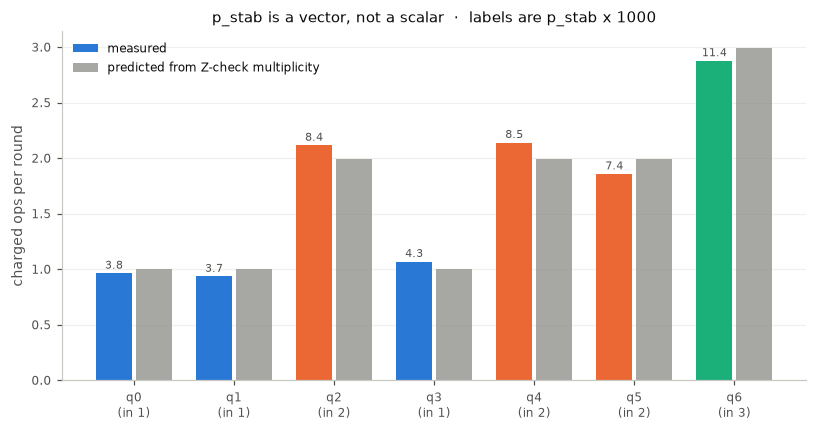

In [10]:
CLASS = {1: BLUE, 2: ORANGE, 3: AQUA}

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(7)
ax.bar(x - 0.2, slope, width=0.36, color=[CLASS[m] for m in MULT], label='measured')
ax.bar(x + 0.2, MULT * np.mean(ops_per_check), width=0.36, color=GRAY, alpha=.75,
       label='predicted from Z-check multiplicity')
for i, (mm, pp) in enumerate(zip(slope, p_stab)):
    ax.annotate(f'{pp*1000:.1f}', (i - 0.2, mm), xytext=(0, 3),
                textcoords='offset points', ha='center', fontsize=7, color=MUTED)
ax.set_xticks(x, [f'q{i}\n(in {m})' for i, m in enumerate(MULT)])
ax.set_ylabel('charged ops per round')
ax.set_title('p_stab is a vector, not a scalar  ·  labels are p_stab x 1000')
ax.grid(axis='y', alpha=.6); ax.set_axisbelow(True); ax.legend()
finish(fig, '04a_p_stab_per_qubit')


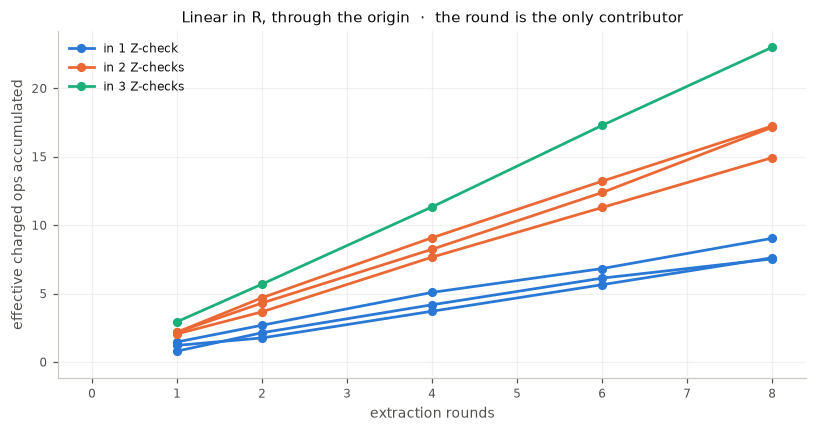

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
seen = set()
for i, q in enumerate(neff.columns):
    m = MULT[i]
    lbl = f'in {m} Z-check{"s" if m > 1 else ""}' if m not in seen else None
    seen.add(m)
    ax.plot(R, neff[q].values, marker='o', ms=5, lw=1.8, color=CLASS[m], label=lbl)
ax.plot([0, R.max()], [0, 0], lw=0)
ax.set_xlabel('extraction rounds'); ax.set_ylabel('effective charged ops accumulated')
ax.set_title('Linear in R, through the origin  ·  the round is the only contributor')
ax.grid(alpha=.6); ax.set_axisbelow(True); ax.legend()
finish(fig, '04b_slope_in_rounds')


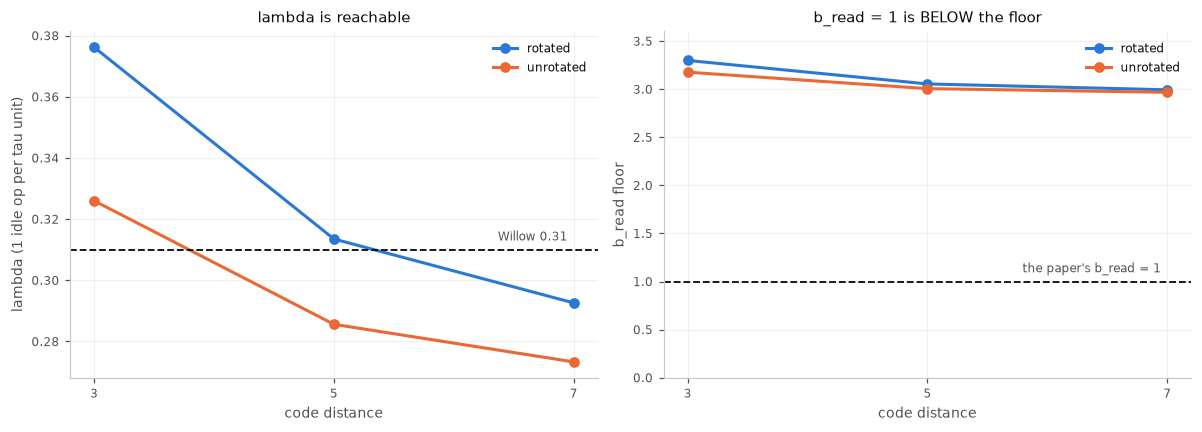

In [12]:
ds = [3, 5, 7]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lab, colour in (('rotated', BLUE), ('unrotated', ORANGE)):
    axes[0].plot(ds, [SURFACE[f'{lab}_d{d}']['lambda_per_idle_op'] for d in ds],
                 marker='o', ms=6, lw=2, color=colour, label=lab)
    axes[1].plot(ds, [SURFACE[f'{lab}_d{d}']['b_read_floor'] for d in ds],
                 marker='o', ms=6, lw=2, color=colour, label=lab)
axes[0].axhline(0.31, color=INK, lw=1.2, ls='--')
axes[0].annotate("Willow 0.31", (7, 0.31), xytext=(-4, 6), textcoords='offset points',
                 ha='right', fontsize=8, color=MUTED)
axes[0].set_ylabel('lambda (1 idle op per tau unit)'); axes[0].set_title('lambda is reachable')
axes[1].axhline(1.0, color=INK, lw=1.2, ls='--')
axes[1].annotate("the paper's b_read = 1", (7, 1.0), xytext=(-4, 6),
                 textcoords='offset points', ha='right', fontsize=8, color=MUTED)
axes[1].set_ylim(0, 3.6)
axes[1].set_ylabel('b_read floor'); axes[1].set_title('b_read = 1 is BELOW the floor')
for a in axes:
    a.set_xlabel('code distance'); a.set_xticks(ds); a.grid(alpha=.6)
    a.set_axisbelow(True); a.legend()
finish(fig, '04c_surface_constants')


## 10. Findings

**1. `p_stab` is a vector, not a scalar.** It follows Z-check multiplicity across the block,
so the seven data qubits fall into three cost classes in the ratio `1:1:2:1:2:2:3`. The paper
applies one number to every data qubit. That is a structural mismatch, not a calibration gap,
and averaging it away hides the fact that `q6` is three times more exposed than `q0`.

**2. The round is the only contributor.** The intercepts sit at zero, so the proxy isolates
the extraction cost cleanly — no encoder, no idling, nothing unaccounted for.

**3. `p_1q` and `p_2q` add.** Which makes `p_2q` usable as the continuous lever on λ, loading
the extraction while leaving idling untouched.

**4. Two routes agree.** The slope-inferred operation count matches the compiled count, so
the noise model is charging what the circuit actually contains.

### Limits

- **The proxy is logically inert.** Data qubits stay in `|0>`, so the ancillas never become
  entangled with them. Depolarizing noise is state-independent, so the charged operations are
  identical — but this is an argument, not a measurement. Section 7 of a later notebook should
  confirm it against the encoded block.
- **Z-sector only.** Per-qubit flips are read in the Z basis, so this measures the X-fault
  rate. The Z-fault rate is equal by symmetry and invisible here.
- **`p_stab` is proportional to `p_1q`**, which is declared rather than measured. Only the
  ratios λ and `b_read` are scale-free.

### Next

1. Feed λ into the τ sweep and see whether the optimum lands where `λτ* = 1/(α−1)` predicts.
2. Confirm the proxy against `|0_L>` with the final-readout syndrome.
3. Decide whether `p_init` belongs in the round — it is a second per-round ancilla cost,
   currently off by choice.